## Fase 1. Preparación

In [ ]:
!nvidia-smi
!pip install -q timm wandb albumentations
from google.colab import drive
drive.mount('/content/drive')
!cp /content/drive/MyDrive/retinopatia/aptos_384.zip /content/
!unzip -q -o /content/aptos_384.zip -d /content/data
!ls /content/data/aptos_384/imagenes | wc -l

Thu Nov 12 15:36:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             34W /   70W |    2493MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import json
import random
import shutil
import time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, average_precision_score,
                             roc_auc_score, balanced_accuracy_score, precision_recall_fscore_support,
                             precision_recall_curve, roc_curve)
from sklearn.preprocessing import label_binarize
import wandb
from google.colab import userdata

SEMILLA = 42
IMG = 384
BATCH = 16
NUM_CLASES = 5
NOMBRES = {0: 'Sin RD', 1: 'Leve', 2: 'Moderada', 3: 'Severa', 4: 'Proliferativa'}
ORDEN = list(NOMBRES.values())
ARQ = 'efficientnet_b0'
NOMBRE_LEGIBLE = 'EfficientNet-B0'
NOMBRE = f'{ARQ}_final_v2'
EPOCAS = 20
CADA_N_EPOCAS = 2
EPOCAS_CABEZA = 2
LR_CABEZA = 1e-3
LR = 3e-4
WD = 1e-2
PROYECTO_WANDB = 'retinopatia-aptos'

IMAGENES = Path('/content/data/aptos_384/imagenes')
DRIVE = Path('/content/drive/MyDrive/retinopatia')
CHECKPOINTS = DRIVE / 'checkpoints' / 'v2'
RESULTADOS = DRIVE / 'resultados' / 'v2'
APP = DRIVE / 'apps' / 'v2'
for carpeta in (CHECKPOINTS, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Activa la GPU: Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4'


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


fijar_semilla(SEMILLA)
df = pd.read_csv(DRIVE / 'particion.csv')
df['path'] = df['id_code'].map(lambda x: str(IMAGENES / f'{x}.png'))
assert all(Path(p).exists() for p in df['path']), 'Faltan imágenes'
f_train = df[df['particion'] == 'train']
f_val = df[df['particion'] == 'val']
f_test = df[df['particion'] == 'test']
wandb.login(key=userdata.get('WANDB_API_KEY'))
print(df['particion'].value_counts())

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


particion
train    2507
val       542
test      534
Name: count, dtype: int64


In [ ]:
def normalizar_color(img_rgb, sigma_rel=30, umbral=10, erosion=3):
    tam = img_rgb.shape[0]
    sigma = tam / sigma_rel
    img = img_rgb.astype(np.float32)
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mascara = (gris > umbral).astype(np.float32)
    nucleo = np.ones((2 * erosion + 1, 2 * erosion + 1), np.uint8)
    mascara = cv2.erode(mascara, nucleo)
    suma = cv2.GaussianBlur(img * mascara[:, :, None], (0, 0), sigma)
    peso = cv2.GaussianBlur(mascara, (0, 0), sigma)[:, :, None]
    desenfoque = suma / np.maximum(peso, 1e-3)
    salida = 4 * img - 4 * desenfoque + 128
    salida = np.clip(salida, 0, 255) * mascara[:, :, None]
    return salida.astype(np.uint8)


MEDIA = (0.485, 0.456, 0.406)
DESV = (0.229, 0.224, 0.225)
tf_train = A.Compose([
    A.Resize(IMG, IMG),
    A.Rotate(limit=180, border_mode=cv2.BORDER_CONSTANT, p=0.8),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=MEDIA, std=DESV),
    ToTensorV2(),
])
tf_eval = A.Compose([A.Resize(IMG, IMG), A.Normalize(mean=MEDIA, std=DESV), ToTensorV2()])


class RetinaDataset(Dataset):
    def __init__(self, df, transform):
        self.rutas = df['path'].tolist()
        self.etiquetas = df['diagnosis'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.rutas[i]), cv2.COLOR_BGR2RGB)
        img = normalizar_color(img)
        return self.transform(image=img)['image'], self.etiquetas[i]


def crear_loaders(df_train, df_val):
    conteo = df_train['diagnosis'].value_counts()
    pesos = df_train['diagnosis'].map(1.0 / conteo).values
    sampler = WeightedRandomSampler(torch.as_tensor(pesos, dtype=torch.double),
                                    num_samples=len(df_train), replacement=True)
    dl_train = DataLoader(RetinaDataset(df_train, tf_train), batch_size=BATCH, sampler=sampler,
                          num_workers=2, pin_memory=True, drop_last=True)
    dl_val = DataLoader(RetinaDataset(df_val, tf_eval), batch_size=BATCH * 2, shuffle=False,
                        num_workers=2, pin_memory=True)
    return dl_train, dl_val

In [ ]:
def crear_modelo():
    return timm.create_model(ARQ, pretrained=True, num_classes=NUM_CLASES).to(DEVICE)


def congelar_cuerpo(modelo, congelar):
    for p in modelo.parameters():
        p.requires_grad = not congelar
    for p in modelo.get_classifier().parameters():
        p.requires_grad = True


def crear_optimizador(modelo, fase):
    if fase == 'cabeza':
        congelar_cuerpo(modelo, True)
        return torch.optim.AdamW(modelo.get_classifier().parameters(), lr=LR_CABEZA, weight_decay=WD), None
    congelar_cuerpo(modelo, False)
    opt = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=WD)
    return opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS - EPOCAS_CABEZA, eta_min=1e-6)


def estado_rng():
    return {'python': random.getstate(), 'numpy': np.random.get_state(),
            'torch': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state_all()}


def restaurar_rng(estado):
    random.setstate(estado['python'])
    np.random.set_state(estado['numpy'])
    torch.set_rng_state(estado['torch'])
    torch.cuda.set_rng_state_all(estado['cuda'])


def entrenar_epoca(modelo, loader, optimizador, scaler, criterio):
    modelo.train()
    perdida_total, aciertos, n = 0.0, 0, 0
    for imgs, y in loader:
        imgs, y = imgs.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            salida = modelo(imgs)
            perdida = criterio(salida, y)
        scaler.scale(perdida).backward()
        scaler.step(optimizador)
        scaler.update()
        perdida_total += perdida.item() * len(y)
        aciertos += (salida.argmax(1) == y).sum().item()
        n += len(y)
    return perdida_total / n, aciertos / n


@torch.no_grad()
def evaluar(modelo, loader, criterio):
    modelo.eval()
    perdida_total, n, todas_y, todas_prob = 0.0, 0, [], []
    for imgs, y in loader:
        imgs, y = imgs.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.amp.autocast('cuda'):
            salida = modelo(imgs)
            perdida = criterio(salida, y)
        perdida_total += perdida.item() * len(y)
        n += len(y)
        todas_y.append(y.cpu())
        todas_prob.append(salida.float().softmax(1).cpu())
    return perdida_total / n, torch.cat(todas_y).numpy(), torch.cat(todas_prob).numpy()

In [ ]:
def ejecutar():
    ruta_ck = CHECKPOINTS / f'{NOMBRE}_ultimo.pt'
    fijar_semilla(SEMILLA)
    modelo = crear_modelo()
    criterio = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda')
    inicio, historial = 0, []

    if ruta_ck.exists():
        ck = torch.load(ruta_ck, map_location='cpu', weights_only=False)
        inicio, historial = ck['epoca'] + 1, ck['historial']
        if inicio >= EPOCAS:
            print('El entrenamiento ya estaba completo')
            return historial
        modelo.load_state_dict(ck['modelo'])
        fase = 'cabeza' if inicio < EPOCAS_CABEZA else 'completa'
        optimizador, scheduler = crear_optimizador(modelo, fase)
        if ck['fase'] == fase:
            optimizador.load_state_dict(ck['optimizador'])
            if scheduler is not None:
                scheduler.load_state_dict(ck['scheduler'])
        scaler.load_state_dict(ck['scaler'])
        restaurar_rng(ck['rng'])
        print(f'Reanudando desde la época {inicio + 1}')
    else:
        fase = 'cabeza'
        optimizador, scheduler = crear_optimizador(modelo, fase)

    dl_train, dl_val = crear_loaders(f_train, f_val)
    run = wandb.init(project=PROYECTO_WANDB, name=NOMBRE, id=NOMBRE, resume='allow',
                     group='entrenamiento_v2', tags=['v2', 'checkpoints_cada_2'],
                     config={'arquitectura': ARQ, 'epocas': EPOCAS, 'img': IMG, 'batch': BATCH,
                             'lr': LR, 'lr_cabeza': LR_CABEZA, 'wd': WD, 'checkpoint_cada': CADA_N_EPOCAS})

    for epoca in range(inicio, EPOCAS):
        if fase == 'cabeza' and epoca >= EPOCAS_CABEZA:
            fase = 'completa'
            optimizador, scheduler = crear_optimizador(modelo, fase)
        t0 = time.time()
        lr_actual = optimizador.param_groups[0]['lr']
        perd_tr, exac_tr = entrenar_epoca(modelo, dl_train, optimizador, scaler, criterio)
        perd_va, y_true, y_prob = evaluar(modelo, dl_val, criterio)
        y_pred = y_prob.argmax(1)
        if scheduler is not None:
            scheduler.step()
        m = {'epoca': epoca + 1, 'fase': fase, 'lr': lr_actual,
             'perdida_train': perd_tr, 'exactitud_train': exac_tr, 'perdida_val': perd_va,
             'exactitud_val': accuracy_score(y_true, y_pred),
             'f1_macro_val': f1_score(y_true, y_pred, average='macro'),
             'qwk_val': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
             'map_val': average_precision_score(label_binarize(y_true, classes=list(NOMBRES)), y_prob, average='macro'),
             'segundos': time.time() - t0}
        historial.append(m)
        wandb.log(m, step=epoca + 1)
        print(f'Época {epoca + 1:2d}/{EPOCAS} | pérdida {perd_tr:.3f}/{perd_va:.3f} | '
              f'exactitud val {m["exactitud_val"]:.3f} | F1 {m["f1_macro_val"]:.3f} | mAP {m["map_val"]:.3f}')

        if (epoca + 1) % CADA_N_EPOCAS == 0 or epoca + 1 == EPOCAS:
            torch.save(modelo.state_dict(), CHECKPOINTS / f'{NOMBRE}_ep{epoca + 1:02d}_pesos.pt')
            torch.save({'modelo': modelo.state_dict(), 'optimizador': optimizador.state_dict(),
                        'scheduler': scheduler.state_dict() if scheduler else None,
                        'scaler': scaler.state_dict(), 'epoca': epoca, 'fase': fase,
                        'historial': historial, 'rng': estado_rng()}, ruta_ck)
            print(f'    checkpoint guardado en la época {epoca + 1}')

    pd.DataFrame(historial).to_csv(RESULTADOS / f'historial_{NOMBRE}.csv', index=False)
    run.finish()
    return historial

## Fase 2. Entrenamiento de 20 épocas (unos 30 minutos)

In [ ]:
ejecutar()

El entrenamiento ya estaba completo


[{'epoca': 1,
  'fase': 'cabeza',
  'lr': 0.001,
  'perdida_train': 2.019912403363448,
  'exactitud_train': 0.3088942307692308,
  'perdida_val': 1.6986187238974764,
  'exactitud_val': 0.3892988929889299,
  'f1_macro_val': 0.298198060316663,
  'qwk_val': np.float64(0.4115417674053894),
  'map_val': np.float64(0.3338810163108432),
  'segundos': 101.8541247844696},
 {'epoca': 2,
  'fase': 'cabeza',
  'lr': 0.001,
  'perdida_train': 1.5609275996685028,
  'exactitud_train': 0.43830128205128205,
  'perdida_val': 1.3618506091987075,
  'exactitud_val': 0.511070110701107,
  'f1_macro_val': 0.3767836280365417,
  'qwk_val': np.float64(0.5621270537042666),
  'map_val': np.float64(0.40628075668989166),
  'segundos': 86.05346393585205},
 {'epoca': 3,
  'fase': 'completa',
  'lr': 0.0003,
  'perdida_train': 1.1188332338172655,
  'exactitud_train': 0.6229967948717948,
  'perdida_val': 0.9698502445572856,
  'exactitud_val': 0.6974169741697417,
  'f1_macro_val': 0.5197559102769349,
  'qwk_val': np.float

## Fase 3. Selección del checkpoint

Validación cruzada de 20 épocas (punto b):
                  mean    std
arquitectura                 
efficientnet_b0  0.820  0.000
resnet50         0.814  0.012

Checkpoint seleccionado: época 20
 epoca  perdida_train  perdida_val  exactitud_train  exactitud_val  f1_macro_val  qwk_val  map_val
     2          1.561        1.362            0.438          0.511         0.377    0.562    0.406
     4          0.732        0.839            0.738          0.729         0.560    0.820    0.585
     6          0.413        0.699            0.840          0.795         0.640    0.859    0.663
     8          0.218        0.823            0.919          0.793         0.614    0.864    0.642
    10          0.151        0.821            0.942          0.803         0.629    0.871    0.655
    12          0.084        0.757            0.972          0.814         0.644    0.870    0.692
    14          0.049        0.860            0.984          0.812         0.638    0.877    0.664
    16    

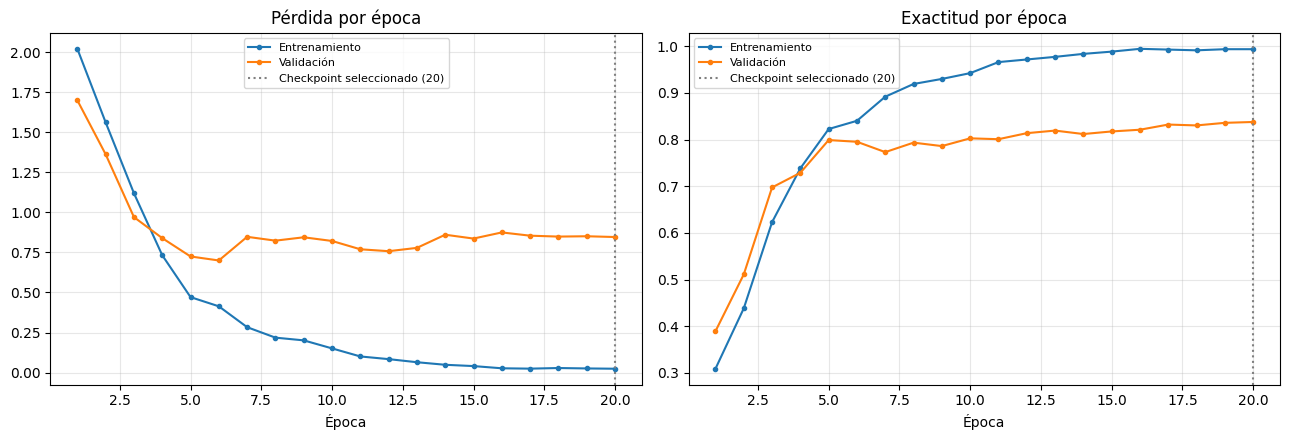

In [ ]:
# Validación cruzada del punto b), hecha en el primer entrenamiento
cv_20 = pd.read_csv(DRIVE / 'resultados' / 'v1' / 'cv_resultados.csv')
print('Validación cruzada de 20 épocas (punto b):')
print(cv_20.groupby('arquitectura')['exactitud'].agg(['mean', 'std']).round(3).to_string())

# Criterio fijado antes de entrenar: mayor exactitud de validación entre los checkpoints.
# idxmax devuelve el primer máximo, así que en caso de empate gana la época más temprana.
h = pd.read_csv(RESULTADOS / f'historial_{NOMBRE}.csv')
guardadas = h[h['epoca'] % CADA_N_EPOCAS == 0]
E_SEL = int(guardadas.loc[guardadas['exactitud_val'].idxmax(), 'epoca'])
print()
print(f'Checkpoint seleccionado: época {E_SEL}')
print(guardadas[['epoca', 'perdida_train', 'perdida_val', 'exactitud_train', 'exactitud_val',
                 'f1_macro_val', 'qwk_val', 'map_val']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(h['epoca'], h['perdida_train'], marker='o', ms=3, label='Entrenamiento')
axes[0].plot(h['epoca'], h['perdida_val'], marker='o', ms=3, label='Validación')
axes[0].set_title('Pérdida por época')
axes[1].plot(h['epoca'], h['exactitud_train'], marker='o', ms=3, label='Entrenamiento')
axes[1].plot(h['epoca'], h['exactitud_val'], marker='o', ms=3, label='Validación')
axes[1].set_title('Exactitud por época')
for ax in axes:
    ax.axvline(E_SEL, color='gray', linestyle=':', label=f'Checkpoint seleccionado ({E_SEL})')
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTADOS / 'seleccion_checkpoint_v2.png', dpi=150)
plt.show()

## Fase 4. Métricas de la época 20 y del checkpoint seleccionado

In [ ]:
def cargar(ruta):
    m = timm.create_model(ARQ, pretrained=False, num_classes=NUM_CLASES)
    m.load_state_dict(torch.load(ruta, map_location=DEVICE))
    return m.to(DEVICE).eval()


def predecir(modelo, df_parte):
    dl = DataLoader(RetinaDataset(df_parte, tf_eval), batch_size=BATCH * 2, shuffle=False,
                    num_workers=2, pin_memory=True)
    return evaluar(modelo, dl, nn.CrossEntropyLoss())


def ece(y_true, y_prob, n_bins=10):
    confianza, acierto = y_prob.max(1), y_prob.argmax(1) == y_true
    bordes, total = np.linspace(0, 1, n_bins + 1), 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        r = (confianza > a) & (confianza <= b)
        if r.any():
            total += r.mean() * abs(acierto[r].mean() - confianza[r].mean())
    return float(total)


def resumen(y_true, y_prob, perdida):
    y_pred = y_prob.argmax(1)
    Y = label_binarize(y_true, classes=list(NOMBRES))
    ap = average_precision_score(Y, y_prob, average=None)
    auc = roc_auc_score(Y, y_prob, average=None)
    p_mac, r_mac, _, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    rep = classification_report(y_true, y_pred, labels=list(NOMBRES), target_names=ORDEN,
                                output_dict=True, zero_division=0)
    ref_real, ref_pred = y_true >= 2, y_pred >= 2
    return {
        'exactitud': float(accuracy_score(y_true, y_pred)),
        'exactitud_balanceada': float(balanced_accuracy_score(y_true, y_pred)),
        'f1_macro': float(f1_score(y_true, y_pred, average='macro')),
        'precision_macro': float(p_mac),
        'exhaustividad_macro': float(r_mac),
        'qwk': float(cohen_kappa_score(y_true, y_pred, weights='quadratic')),
        'map': float(ap.mean()),
        'auc_macro': float(auc.mean()),
        'mae_niveles': float(np.abs(y_pred - y_true).mean()),
        'exactitud_mas_menos_1': float((np.abs(y_pred - y_true) <= 1).mean()),
        'perdida': float(perdida),
        'brier': float(((y_prob - Y) ** 2).sum(axis=1).mean()),
        'ece': ece(y_true, y_prob),
        'confianza_media_errores': float(y_prob.max(1)[y_pred != y_true].mean()),
        'sensibilidad_referible': float((ref_pred & ref_real).sum() / ref_real.sum()),
        'especificidad_referible': float((~ref_pred & ~ref_real).sum() / (~ref_real).sum()),
        'por_clase': {c: {'precision': float(rep[c]['precision']), 'exhaustividad': float(rep[c]['recall']),
                          'f1': float(rep[c]['f1-score']), 'ap': float(ap[i]), 'auc': float(auc[i]),
                          'soporte': int(rep[c]['support'])} for i, c in enumerate(ORDEN)},
        'matriz_confusion': confusion_matrix(y_true, y_pred, labels=list(NOMBRES)).tolist(),
    }


filas, resultados_sel = [], {}
for e in sorted({EPOCAS, E_SEL}):
    ruta = CHECKPOINTS / f'{NOMBRE}_ep{e:02d}_pesos.pt'
    modelo = cargar(ruta)
    _, yt, yp = predecir(modelo, f_train)
    exac_train = accuracy_score(yt, yp.argmax(1))
    for parte, df_parte, corto in [('validacion', f_val, 'val'), ('prueba', f_test, 'test')]:
        perdida, y_true, y_prob = predecir(modelo, df_parte)
        r = resumen(y_true, y_prob, perdida)
        if e == E_SEL:
            resultados_sel[parte] = r
            salida = df_parte[['id_code', 'diagnosis', 'clase', 'tamano']].reset_index(drop=True).copy()
            salida['pred'] = y_prob.argmax(1)
            for k in NOMBRES:
                salida[f'p_{k}'] = y_prob[:, k]
            salida.to_csv(RESULTADOS / f'predicciones_{corto}_v2.csv', index=False)
        simples = {k: v for k, v in r.items() if not isinstance(v, (dict, list))}
        filas.append({'epoca': e, 'seleccionada': e == E_SEL, 'conjunto': parte,
                      'exactitud_train_limpia': exac_train, 'brecha_limpia': exac_train - r['exactitud'], **simples})
    if e == E_SEL:
        parametros = int(sum(p.numel() for p in modelo.parameters()))
        tamano_mb = round(ruta.stat().st_size / 1e6, 1)
    del modelo
    torch.cuda.empty_cache()

filas_cv = cv_20[cv_20['arquitectura'] == ARQ]
metricas = {
    'clases': ORDEN, 'modelo': NOMBRE_LEGIBLE, 'arquitectura': ARQ,
    'epoca_seleccionada': E_SEL, 'epocas_entrenadas': EPOCAS,
    'criterio_seleccion': 'Checkpoint con mayor exactitud de validación entre los guardados cada 2 épocas',
    'parametros': parametros, 'tamano_mb': tamano_mb,
    'validacion_cruzada': {'exactitud_media': float(filas_cv['exactitud'].mean()),
                           'exactitud_desv': float(filas_cv['exactitud'].std()),
                           'f1_macro_media': float(filas_cv['f1_macro'].mean()),
                           'qwk_media': float(filas_cv['qwk'].mean())},
    'validacion': resultados_sel['validacion'], 'prueba': resultados_sel['prueba'],
    'historial': h[['epoca', 'perdida_train', 'perdida_val', 'exactitud_train', 'exactitud_val',
                    'f1_macro_val', 'qwk_val', 'map_val']].round(4).to_dict('records'),
}
with open(RESULTADOS / 'metricas_v2.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)

comparacion = pd.DataFrame(filas)
comparacion.to_csv(RESULTADOS / 'comparacion_epocas_v2.csv', index=False)
print(comparacion[['epoca', 'seleccionada', 'conjunto', 'exactitud', 'exactitud_balanceada', 'f1_macro',
                   'qwk', 'map', 'auc_macro', 'ece', 'perdida', 'exactitud_train_limpia',
                   'brecha_limpia']].round(3).to_string(index=False))

 epoca  seleccionada   conjunto  exactitud  exactitud_balanceada  f1_macro   qwk   map  auc_macro   ece  perdida  exactitud_train_limpia  brecha_limpia
    20          True validacion      0.838                 0.657     0.678 0.889 0.680      0.929 0.117    0.846                   0.999          0.161
    20          True     prueba      0.830                 0.655     0.663 0.905 0.688      0.938 0.112    0.719                   0.999          0.169


## Fase 5. Curvas de rendimiento

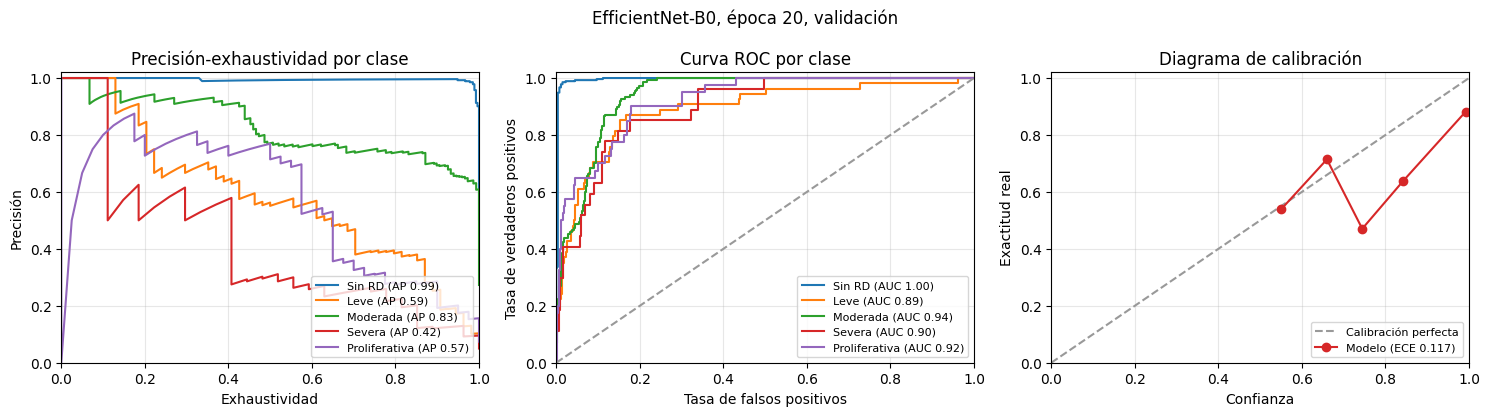

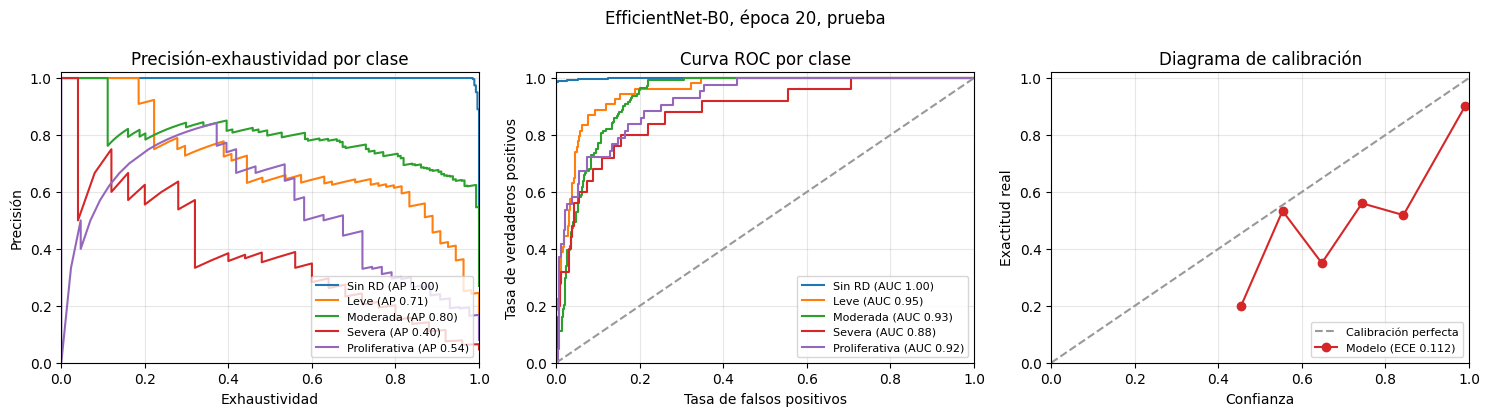

In [ ]:
def figuras_rendimiento(y_true, y_prob, titulo, archivo):
    Y = label_binarize(y_true, classes=list(NOMBRES))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for k, nombre in NOMBRES.items():
        p, r, _ = precision_recall_curve(Y[:, k], y_prob[:, k])
        axes[0].plot(r, p, label=f'{nombre} (AP {average_precision_score(Y[:, k], y_prob[:, k]):.2f})')
        fpr, tpr, _ = roc_curve(Y[:, k], y_prob[:, k])
        axes[1].plot(fpr, tpr, label=f'{nombre} (AUC {roc_auc_score(Y[:, k], y_prob[:, k]):.2f})')
    axes[0].set(title='Precisión-exhaustividad por clase', xlabel='Exhaustividad', ylabel='Precisión')
    axes[1].plot([0, 1], [0, 1], '--', color='0.6')
    axes[1].set(title='Curva ROC por clase', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
    confianza, acierto = y_prob.max(1), y_prob.argmax(1) == y_true
    bordes = np.linspace(0, 1, 11)
    centros, exactitudes = [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        r = (confianza > a) & (confianza <= b)
        if r.sum() >= 5:
            centros.append(confianza[r].mean())
            exactitudes.append(acierto[r].mean())
    axes[2].plot([0, 1], [0, 1], '--', color='0.6', label='Calibración perfecta')
    axes[2].plot(centros, exactitudes, 'o-', color='tab:red', label=f'Modelo (ECE {ece(y_true, y_prob):.3f})')
    axes[2].set(title='Diagrama de calibración', xlabel='Confianza', ylabel='Exactitud real')
    for ax in axes:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='lower right')
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(RESULTADOS / archivo, dpi=150)
    plt.show()


for parte, corto in [('validación', 'val'), ('prueba', 'test')]:
    pred = pd.read_csv(RESULTADOS / f'predicciones_{corto}_v2.csv')
    figuras_rendimiento(pred['diagnosis'].to_numpy(), pred[[f'p_{k}' for k in NOMBRES]].to_numpy(),
                        f'{NOMBRE_LEGIBLE}, época {E_SEL}, {parte}', f'rendimiento_{corto}_v2.png')

## Fase 6. Punto c)

EfficientNet-B0, checkpoint de la época 20
               precision    recall  f1-score   support

       Sin RD      0.989     0.978     0.983       273
         Leve      0.560     0.519     0.538        54
     Moderada      0.734     0.858     0.791       148
       Severa      0.524     0.407     0.458        27
Proliferativa      0.750     0.525     0.618        40

     accuracy                          0.838       542
    macro avg      0.711     0.657     0.678       542
 weighted avg      0.836     0.838     0.833       542



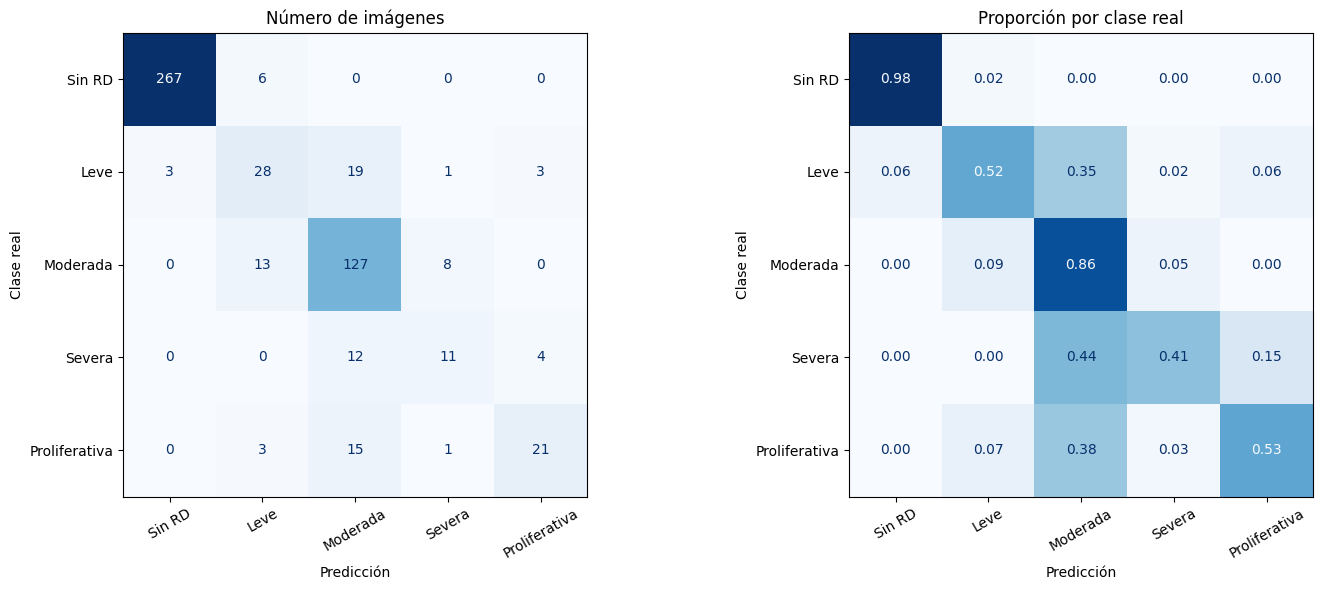

             n  exactitud  referencia
tamano                               
1050x1050  140      0.979       0.943
2416x1736   89      0.573       0.337
2588x1958   89      0.820       0.427
3216x2136   62      0.806       0.758
819x614     50      1.000       1.000
2048x1536   43      1.000       1.000
3388x2588   25      0.720       0.600


In [ ]:
pred_val = pd.read_csv(RESULTADOS / 'predicciones_val_v2.csv')
y_true, y_pred = pred_val['diagnosis'], pred_val['pred']
print(f'{NOMBRE_LEGIBLE}, checkpoint de la época {E_SEL}')
print(classification_report(y_true, y_pred, labels=list(NOMBRES), target_names=ORDEN, digits=3, zero_division=0))
pd.DataFrame(classification_report(y_true, y_pred, labels=list(NOMBRES), target_names=ORDEN, digits=3,
                                   zero_division=0, output_dict=True)).T.round(3).to_csv(
    RESULTADOS / 'metricas_validacion_v2.csv')

cm = confusion_matrix(y_true, y_pred, labels=list(NOMBRES))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=ORDEN).plot(ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=30)
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=ORDEN).plot(
    ax=axes[1], cmap='Blues', colorbar=False, xticks_rotation=30, values_format='.2f')
axes[0].set_title('Número de imágenes')
axes[1].set_title('Proporción por clase real')
for ax in axes:
    ax.set(xlabel='Predicción', ylabel='Clase real')
plt.tight_layout()
plt.savefig(RESULTADOS / 'matriz_confusion_val_v2.png', dpi=150)
plt.show()

pred_val['acierto'] = pred_val['diagnosis'] == pred_val['pred']
por_camara = pred_val.groupby('tamano').agg(
    n=('acierto', 'size'), exactitud=('acierto', 'mean'),
    referencia=('diagnosis', lambda s: s.value_counts(normalize=True).max()))
por_camara = por_camara[por_camara['n'] >= 20].sort_values('n', ascending=False).round(3)
por_camara.to_csv(RESULTADOS / 'exactitud_por_camara_v2.csv')
print(por_camara)

## Fase 7. Punto d)

Exactitud en prueba: 0.830 | errores: 91 | entre vecinos: 68


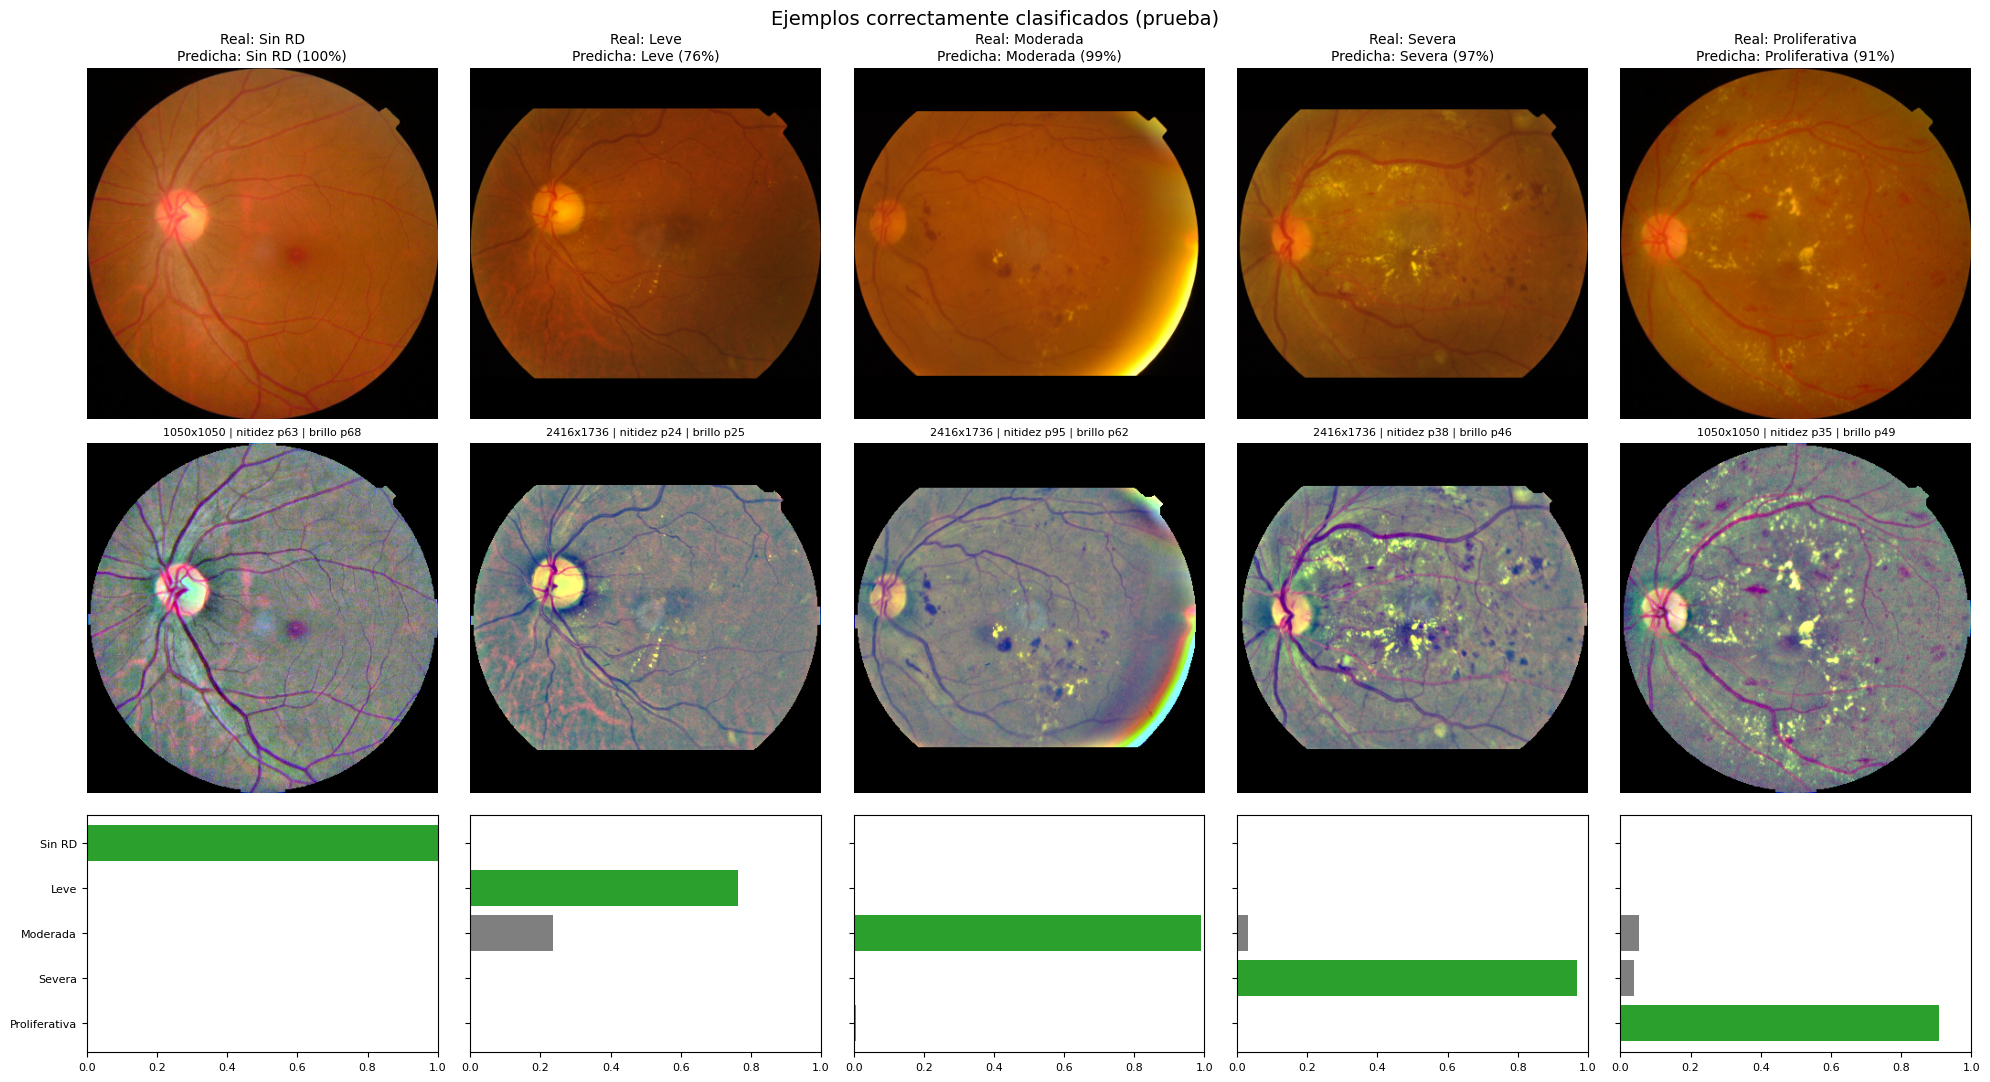

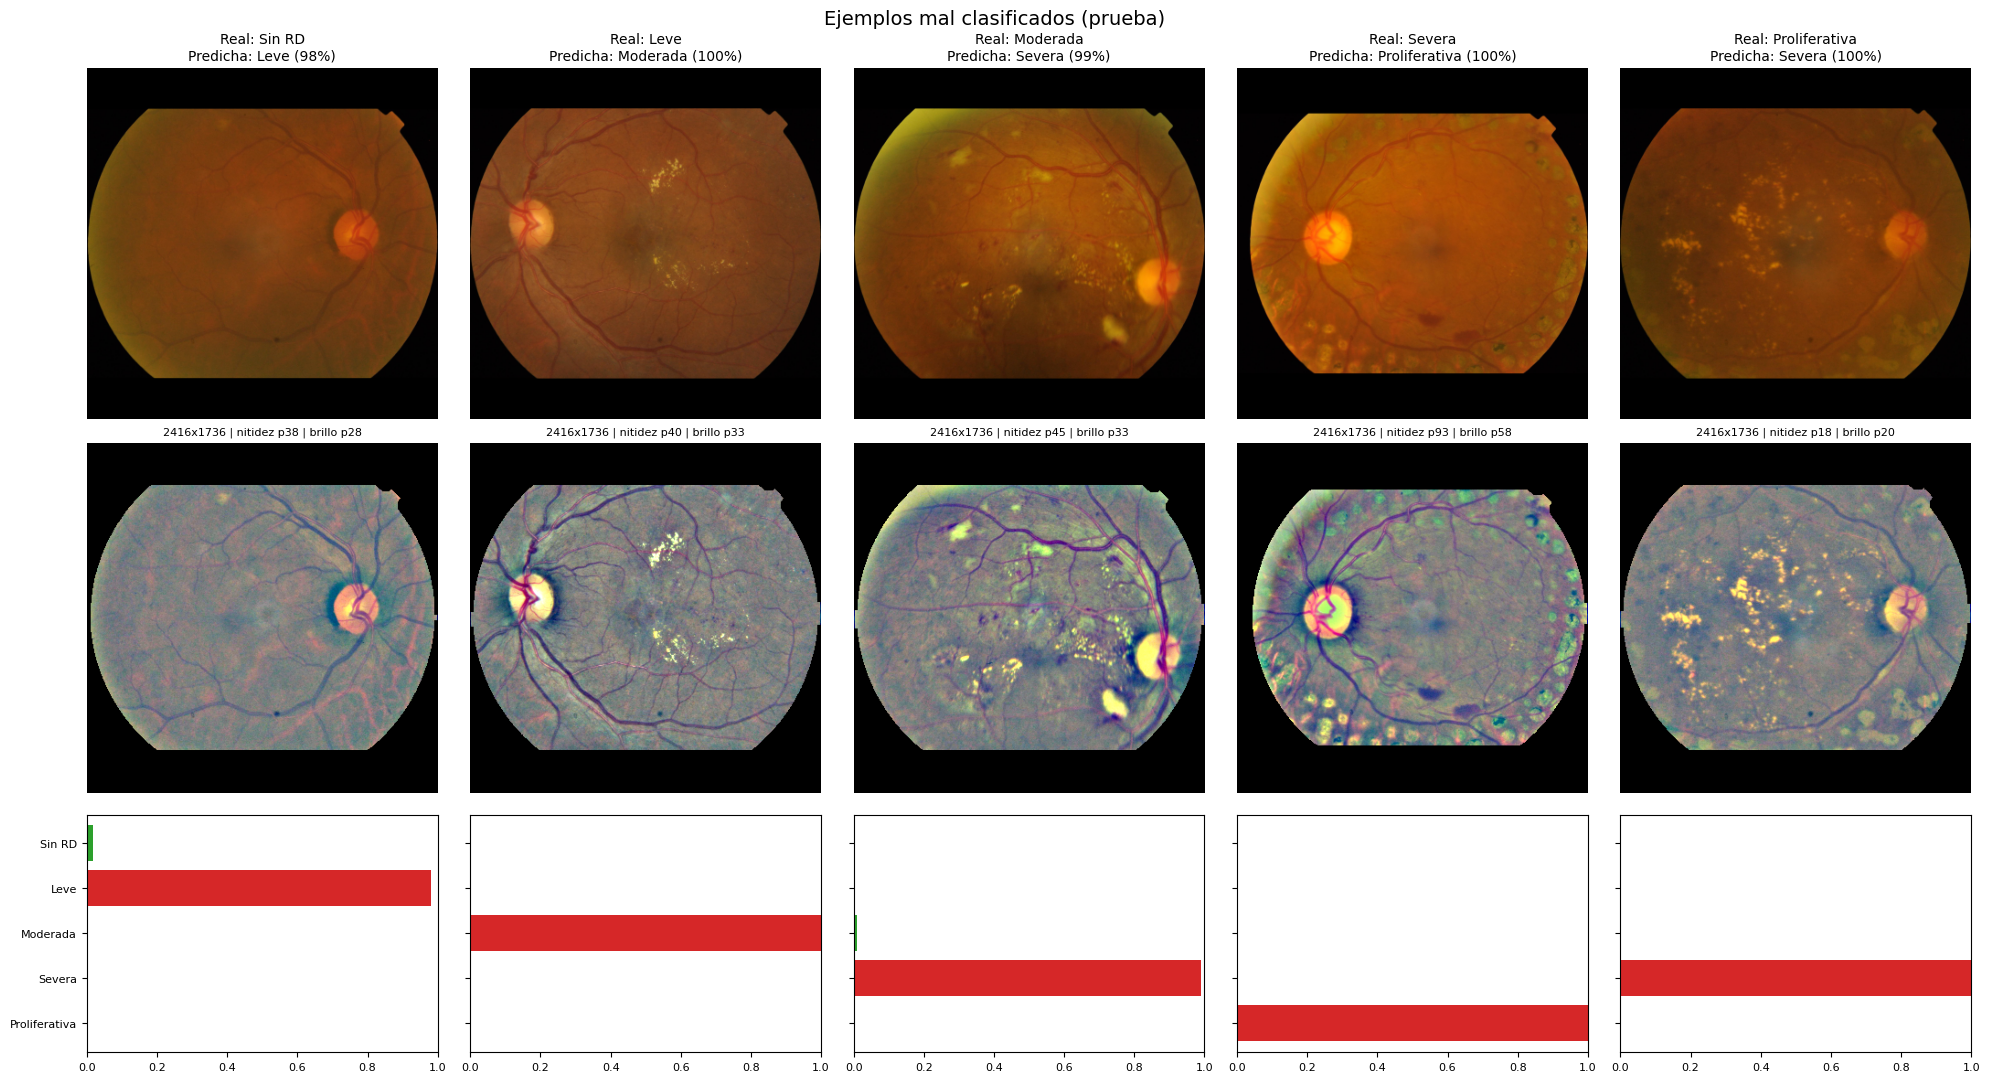

    tipo      id_code         clase          pred  confianza  salto    tamano  nitidez_pct  brillo_pct
Correcto b9bc81fcb075        Sin RD        Sin RD       1.00      0 1050x1050         0.63        0.68
Correcto 494fc9c745a3          Leve          Leve       0.76      0 2416x1736         0.24        0.25
Correcto a8652b2de23f      Moderada      Moderada       0.99      0 2416x1736         0.95        0.62
Correcto 91cf56d3d1af        Severa        Severa       0.97      0 2416x1736         0.38        0.46
Correcto 70d657f8f503 Proliferativa Proliferativa       0.91      0 1050x1050         0.35        0.49
   Error cb0cc98d7e35        Sin RD          Leve       0.98      1 2416x1736         0.38        0.28
   Error 1bb0ddfe753a          Leve      Moderada       1.00      1 2416x1736         0.40        0.33
   Error d952dbfb0fe4      Moderada        Severa       0.99      1 2416x1736         0.45        0.33
   Error af3b0115aad1        Severa Proliferativa       1.00      1 2416x

In [ ]:
pt = pd.read_csv(RESULTADOS / 'predicciones_test_v2.csv')
pt['confianza'] = pt[[f'p_{k}' for k in NOMBRES]].max(axis=1)
pt['acierto'] = pt['diagnosis'] == pt['pred']
pt['salto'] = (pt['pred'] - pt['diagnosis']).abs()
pt['path'] = pt['id_code'].map(lambda x: str(IMAGENES / f'{x}.png'))


def calidad(ruta):
    gris = cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2GRAY)
    mascara = gris > 10
    return cv2.Laplacian(gris, cv2.CV_64F)[mascara].var(), gris[mascara].mean()


pt['nitidez'], pt['brillo'] = zip(*pt['path'].map(calidad))
pt['nitidez_pct'] = pt['nitidez'].rank(pct=True)
pt['brillo_pct'] = pt['brillo'].rank(pct=True)
print(f'Exactitud en prueba: {pt["acierto"].mean():.3f} | errores: {(~pt["acierto"]).sum()} | '
      f'entre vecinos: {(pt["salto"] == 1).sum()}')

correctos = pt[pt['acierto']].groupby('diagnosis').sample(n=1, random_state=SEMILLA).sort_values('diagnosis')
errores = pt[~pt['acierto']].sort_values('confianza', ascending=False)
sel_err = errores.drop_duplicates('diagnosis').head(5)
if len(sel_err) < 5:
    resto = errores.drop(sel_err.index).drop_duplicates(['diagnosis', 'pred'])
    sel_err = pd.concat([sel_err, resto.head(5 - len(sel_err))])
sel_err = sel_err.sort_values('diagnosis')


def mostrar_ejemplos(sel, titulo, archivo):
    n = len(sel)
    fig, axes = plt.subplots(3, n, figsize=(4 * n, 11), gridspec_kw={'height_ratios': [3, 3, 2]})
    for j, (_, f) in enumerate(sel.iterrows()):
        img = cv2.cvtColor(cv2.imread(f['path']), cv2.COLOR_BGR2RGB)
        real, pred = int(f['diagnosis']), int(f['pred'])
        axes[0, j].imshow(img)
        axes[0, j].set_title(f'Real: {NOMBRES[real]}\nPredicha: {NOMBRES[pred]} ({f["confianza"]:.0%})', fontsize=10)
        axes[1, j].imshow(normalizar_color(img))
        axes[1, j].set_title(f'{f["tamano"]} | nitidez p{f["nitidez_pct"] * 100:.0f} | '
                             f'brillo p{f["brillo_pct"] * 100:.0f}', fontsize=8)
        colores = ['tab:green' if k == real else 'tab:red' if k == pred else 'tab:gray' for k in NOMBRES]
        axes[2, j].barh(ORDEN, [f[f'p_{k}'] for k in NOMBRES], color=colores)
        axes[2, j].set_xlim(0, 1)
        axes[2, j].invert_yaxis()
        axes[2, j].tick_params(labelsize=8)
        if j > 0:
            axes[2, j].set_yticklabels([])
    for ax in axes[:2].flat:
        ax.axis('off')
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.savefig(RESULTADOS / archivo, dpi=150)
    plt.show()


mostrar_ejemplos(correctos, 'Ejemplos correctamente clasificados (prueba)', 'ejemplos_correctos_v2.png')
mostrar_ejemplos(sel_err, 'Ejemplos mal clasificados (prueba)', 'ejemplos_errores_v2.png')
cols = ['id_code', 'clase', 'pred', 'confianza', 'salto', 'tamano', 'nitidez_pct', 'brillo_pct']
tabla_d = pd.concat([correctos.assign(tipo='Correcto'), sel_err.assign(tipo='Error')])[['tipo'] + cols]
tabla_d['pred'] = tabla_d['pred'].map(NOMBRES)
tabla_d.round(2).to_csv(RESULTADOS / 'ejemplos_punto_d_v2.csv', index=False)
print(tabla_d.round(2).to_string(index=False))
print(pt.groupby('acierto')[['confianza', 'nitidez_pct', 'brillo_pct']].median().round(2))

## Fase 8. Archivos para la app

In [ ]:
for sub in ['modelo', 'datos', 'ejemplos']:
    (APP / sub).mkdir(parents=True, exist_ok=True)
shutil.copy(CHECKPOINTS / f'{NOMBRE}_ep{E_SEL:02d}_pesos.pt', APP / 'modelo' / f'{ARQ}_final_pesos.pt')
shutil.copy(RESULTADOS / 'predicciones_test_v2.csv', APP / 'datos' / 'predicciones_test.csv')
shutil.copy(RESULTADOS / 'metricas_v2.json', APP / 'datos' / 'metricas.json')
pd.read_csv(APP / 'datos' / 'predicciones_test.csv')[['id_code', 'diagnosis']].to_csv(
    APP / 'datos' / 'etiquetas_test.csv', index=False)
for id_code in pd.read_csv(RESULTADOS / 'ejemplos_punto_d_v2.csv')['id_code']:
    shutil.copy(IMAGENES / f'{id_code}.png', APP / 'ejemplos')
print('Carpeta lista:', APP)
for sub in ['modelo', 'datos', 'ejemplos']:
    print(f'  {sub}/:', sorted(p.name for p in (APP / sub).iterdir()))
print('Época seleccionada:', E_SEL)

Carpeta lista: /content/drive/MyDrive/retinopatia/apps/v2
  modelo/: ['efficientnet_b0_final_pesos.pt']
  datos/: ['etiquetas_test.csv', 'metricas.json', 'predicciones_test.csv']
  ejemplos/: ['1bb0ddfe753a.png', '312694ea8e6a.png', '494fc9c745a3.png', '70d657f8f503.png', '91cf56d3d1af.png', 'a8652b2de23f.png', 'af3b0115aad1.png', 'b9bc81fcb075.png', 'cb0cc98d7e35.png', 'd952dbfb0fe4.png']
Época seleccionada: 20
